## 샘플러: DDPM과 DDIM
1. 샘플러는 학습한 모델로 순수 노이즈 x_1000에서 x_0까지 되돌리는 생성 절차다. 모델은 x_t에 섞인 노이즈의 예측값 ε̂(엡실론 햇)만 계산하므로, 같은 모델로 샘플러만 바꿔 쓸 수 있다.
2. 학습 식 x_t = √ᾱ_t·x_0 + √(1−ᾱ_t)·ε를 x_0에 대해 풀면 한 번에 복원하는 식이 된다.
   - x̂_0 = (x_t − √(1−ᾱ_t)·ε̂) / √ᾱ_t
3. 한 번에 복원하면 숫자 이미지가 나오지 않으므로, 여러 단계로 나누어 되돌린다.
   - ε̂의 오차가 √(1−ᾱ_t)/√ᾱ_t배로 커진다. 이 배율은 t = 400에서 2.0, t = 1000에서 157.4다.
   - 노이즈가 많은 x_t로는 원본을 정할 수 없다. 그래서 ε̂는 가능한 숫자들의 평균에 가깝고, x̂_0은 여러 숫자가 겹친 이미지가 된다.
4. DDPM은 t에서 t−1로 한 칸씩 1000번 이동하고, 단계마다 새 노이즈 z를 더한다. 01의 `sample`과 `denoise`가 이 방식이다.
   - x_{t−1} = (x_t − (1−α_t)/√(1−ᾱ_t)·ε̂) / √α_t + σ_t·z
5. DDIM은 한 단계에서 x̂_0을 추정한 뒤, x̂_0과 ε̂를 학습 식에 넣어 노이즈가 더 적은 시점 s의 x를 만든다.
   - x_s = √ᾱ_s·x̂_0 + √(1−ᾱ_s)·ε̂
   - s를 t 가까이 고르면 ε̂의 오차가 거의 커지지 않는다. t = 1000에서 s = 980으로 갈 때 배율은 0.22다.
   - 그래서 1000, 980, …, 20처럼 20칸씩 건너뛰어 50단계로 생성할 수 있다.
   - 새 노이즈를 더하지 않으므로, 시작 노이즈가 같으면 결과 이미지도 같다.
6. DDIM을 구현할 때는 학습 때의 1000단계 ᾱ 표를 그대로 쓰고 시점만 골라 쓴다. `Diffuser(num_timesteps=50)`로 표를 새로 만들면 ᾱ 값이 학습 때와 달라진다. 마지막 단계의 s = 0에서는 ᾱ_0 = 1이다.

## 코드
### 04에서 가져온 부분
- 04에서 학습한 UNet과 디코더를 불러온다. 다시 학습하지 않는다.
  - 04를 먼저 실행해서 `./data/04_unet_attention.pt`를 만들어야 한다.
- 클래스 정의는 04와 같다. VAE는 생성에 디코더만 쓰므로 `Decoder`만 가져온다.

In [1]:
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
from torch import nn
from torch.optim import Adam
from torch.utils.data import DataLoader, Dataset, TensorDataset
from torchvision import transforms
from tqdm import tqdm

NUM_CLASSES = 10
NULL_LABEL = NUM_CLASSES  # 레이블 0~9 다음 번호인 10을 '조건 없음' ∅로 쓴다.

def pos_encoding(ts, output_dim, device='cpu'):
    i = torch.arange(output_dim, device=device)
    div_term = 10000 ** (i / output_dim)
    angles = ts.to(device).float()[:, None] / div_term[None, :]
    v = torch.zeros(len(ts), output_dim, device=device)
    v[:, 0::2] = torch.sin(angles[:, 0::2])
    v[:, 1::2] = torch.cos(angles[:, 1::2])
    return v


class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_embed_dim):
        super().__init__()
        self.convs = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU()
        )
        self.mlp = nn.Sequential(
            nn.Linear(time_embed_dim, in_ch),
            nn.ReLU(),
            nn.Linear(in_ch, in_ch)
        )

    def forward(self, x, v):
        N, C, _, _ = x.shape
        v = self.mlp(v)
        v = v.view(N, C, 1, 1)
        y = self.convs(x + v)
        return y

class Attention(nn.Module):
    def __init__(self, query_dim, context_dim, num_heads):
        super().__init__()
        self.num_heads = num_heads
        self.to_q = nn.Linear(query_dim, query_dim, bias=False)    # W_q
        self.to_k = nn.Linear(context_dim, query_dim, bias=False)  # W_k
        self.to_v = nn.Linear(context_dim, query_dim, bias=False)  # W_v
        self.to_out = nn.Linear(query_dim, query_dim)              # W_o
        self.attn_map = None

    def forward(self, x, context=None):
        context = x if context is None else context  # context가 없으면 셀프어텐션, 있으면 크로스어텐션이다.
        N, L, d = x.shape
        h = self.num_heads
        d_k = d // h

        q = self.to_q(x).view(N, L, h, d_k).transpose(1, 2)        # Q: (N, h, L, d_k)
        k = self.to_k(context).view(N, -1, h, d_k).transpose(1, 2)  # K: (N, h, M, d_k)
        v = self.to_v(context).view(N, -1, h, d_k).transpose(1, 2)  # V: (N, h, M, d_k)

        scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)  # S = Q·Kᵀ/√d_k: (N, h, L, M)
        attn = scores.softmax(dim=-1)                       # A: 행마다 합이 1
        self.attn_map = attn.detach()
        out = attn @ v                                      # A·V: (N, h, L, d_k)
        out = out.transpose(1, 2).reshape(N, L, d)          # 헤드 h개를 열 방향으로 concat: (N, L, h·d_k)
        return self.to_out(out)


class TransformerBlock(nn.Module):
    def __init__(self, ch, context_dim, num_heads=4):
        super().__init__()
        self.norm_in = nn.GroupNorm(8, ch)
        self.norm1 = nn.LayerNorm(ch)
        self.self_attn = Attention(ch, ch, num_heads)
        self.norm2 = nn.LayerNorm(ch)
        self.cross_attn = Attention(ch, context_dim, num_heads)
        self.norm3 = nn.LayerNorm(ch)
        self.ff = nn.Sequential(nn.Linear(ch, 4 * ch), nn.GELU(), nn.Linear(4 * ch, ch))

    def forward(self, x, context):
        N, C, H, W = x.shape
        h = self.norm_in(x).flatten(2).transpose(1, 2)   # (N, H·W, C): 위치 하나가 토큰 하나
        h = h + self.self_attn(self.norm1(h))             # 위치끼리 참고한다.
        h = h + self.cross_attn(self.norm2(h), context)   # 위치마다 조건 토큰을 참고한다.
        h = h + self.ff(self.norm3(h))
        h = h.transpose(1, 2).reshape(N, C, H, W)
        return x + h


class UNetAttn(nn.Module):
    def __init__(self, in_ch=4, time_embed_dim=100, context_dim=64, num_tokens=2):
        super().__init__()
        self.time_embed_dim = time_embed_dim
        self.token_emb = nn.Embedding(NUM_CLASSES + 1, context_dim)        # 레이블 0~9와 ∅
        self.pos_emb = nn.Parameter(torch.zeros(num_tokens, context_dim))  # 토큰 순서

        self.down1 = ConvBlock(in_ch, 64, time_embed_dim)
        self.attn_down1 = TransformerBlock(64, context_dim)
        self.down2 = ConvBlock(64, 128, time_embed_dim)
        self.attn_down2 = TransformerBlock(128, context_dim)
        self.bot1 = ConvBlock(128, 256, time_embed_dim)
        self.attn_bot1 = TransformerBlock(256, context_dim)
        self.up2 = ConvBlock(256 + 128, 128, time_embed_dim)
        self.attn_up2 = TransformerBlock(128, context_dim)
        self.up1 = ConvBlock(128 + 64, 64, time_embed_dim)
        self.attn_up1 = TransformerBlock(64, context_dim)
        self.out = nn.Conv2d(64, in_ch, 1)

        self.maxpool = nn.MaxPool2d(2)
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear')

    def forward(self, x, timesteps, labels):
        t = pos_encoding(timesteps, self.time_embed_dim, device=x.device)
        context = self.token_emb(labels) + self.pos_emb  # y: (N, 2, context_dim)

        x1 = self.attn_down1(self.down1(x, t), context)  # (N, 64, 8, 16)
        x = self.maxpool(x1)
        x2 = self.attn_down2(self.down2(x, t), context)  # (N, 128, 4, 8)
        x = self.maxpool(x2)

        x = self.attn_bot1(self.bot1(x, t), context)     # (N, 256, 2, 4)

        x = self.upsample(x)
        x = torch.cat([x, x2], dim=1)
        x = self.attn_up2(self.up2(x, t), context)       # (N, 128, 4, 8)
        x = self.upsample(x)
        x = torch.cat([x, x1], dim=1)
        x = self.attn_up1(self.up1(x, t), context)       # (N, 64, 8, 16)

        x = self.out(x)
        return x

class Decoder(nn.Module):
    def __init__(self, latent_ch):
        super().__init__()
        self.convs = nn.Sequential(
            nn.Conv2d(latent_ch, 64, 3, padding=1),              # (N, 64, 8, 16)
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),  # (N, 32, 16, 32)
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1),   # (N, 1, 32, 64)
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.convs(z)


latent_ch = 4
device = torch.accelerator.current_accelerator() if torch.accelerator.is_available() else torch.device('cpu')

checkpoint = torch.load('./data/04_unet_attention.pt', map_location=device)
model = UNetAttn(in_ch=latent_ch).to(device)
model.load_state_dict(checkpoint['unet'])
model.eval()
decoder = Decoder(latent_ch).to(device)
decoder.load_state_dict(checkpoint['decoder'])
scale_factor = checkpoint['scale_factor']

### DDPM과 DDIM 샘플러
- `guided_noise`는 04와 같다. 두 샘플러 모두 모델은 ε̂를 계산하는 데만 쓴다.
- `ddpm_sample`은 04의 `sample`과 같은 계산이다. 시작 노이즈를 인자로 받게만 바꿨다.
- `ddim_sample`은 정리 5번의 두 식을 그대로 옮긴 것이다.
  - ᾱ 표는 학습 때의 1000단계 표를 그대로 쓰고, `torch.linspace`로 시점만 골라 쓴다. 50단계면 1000, 980, …, 20, 0이다.
  - 마지막 시점 s = 0에서 쓰도록 ᾱ_0 = 1을 표 앞에 붙인다.

In [2]:
class Diffuser:
    def __init__(self, num_timesteps=1000, beta_start=0.0001, beta_end=0.02, device='cpu'):
        self.num_timesteps = num_timesteps
        self.device = device
        self.betas = torch.linspace(beta_start, beta_end, num_timesteps, device=device)
        self.alphas = 1 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)
        # ᾱ_0 = 1을 앞에 붙여서, DDIM에서 alpha_bars_from_0[t]가 그대로 ᾱ_t가 되게 한다.
        self.alpha_bars_from_0 = torch.cat([torch.ones(1, device=device), self.alpha_bars])

    def guided_noise(self, model, x, t, labels, guidance_scale):
        null_labels = torch.full_like(labels, NULL_LABEL)
        eps = model(torch.cat([x, x]), torch.cat([t, t]), torch.cat([labels, null_labels]))
        eps_cond, eps_uncond = eps.chunk(2)
        return eps_uncond + guidance_scale * (eps_cond - eps_uncond)

    def ddpm_step(self, model, x, t, labels, guidance_scale):
        t_idx = t - 1
        alpha = self.alphas[t_idx].view(-1, 1, 1, 1)
        alpha_bar = self.alpha_bars[t_idx].view(-1, 1, 1, 1)
        alpha_bar_prev = self.alpha_bars[t_idx - 1].view(-1, 1, 1, 1)

        eps = self.guided_noise(model, x, t, labels, guidance_scale)
        noise = torch.randn_like(x)
        noise[t == 1] = 0

        mu = (x - ((1 - alpha) / torch.sqrt(1 - alpha_bar)) * eps) / torch.sqrt(alpha)
        std = torch.sqrt((1 - alpha) * (1 - alpha_bar_prev) / (1 - alpha_bar))
        return mu + noise * std  # 단계마다 새 노이즈를 더한다.

    @torch.no_grad()
    def ddpm_sample(self, model, x, labels, guidance_scale):
        for i in tqdm(range(self.num_timesteps, 0, -1)):
            t = torch.full((len(x),), i, device=self.device, dtype=torch.long)
            x = self.ddpm_step(model, x, t, labels, guidance_scale)
        return x

    def ddim_step(self, model, x, t, s, labels, guidance_scale):
        alpha_bar_t = self.alpha_bars_from_0[t].view(-1, 1, 1, 1)
        alpha_bar_s = self.alpha_bars_from_0[s].view(-1, 1, 1, 1)

        eps = self.guided_noise(model, x, t, labels, guidance_scale)
        x0_hat = (x - torch.sqrt(1 - alpha_bar_t) * eps) / torch.sqrt(alpha_bar_t)  # ① x̂_0 추정
        return torch.sqrt(alpha_bar_s) * x0_hat + torch.sqrt(1 - alpha_bar_s) * eps  # ② 시점 s로 다시 섞기

    @torch.no_grad()
    def ddim_sample(self, model, x, labels, guidance_scale, num_steps=50):
        timesteps = torch.linspace(self.num_timesteps, 0, num_steps + 1, device=self.device).long()
        for t, s in zip(timesteps[:-1], timesteps[1:]):
            t_batch = torch.full((len(x),), t.item(), device=self.device, dtype=torch.long)
            s_batch = torch.full((len(x),), s.item(), device=self.device, dtype=torch.long)
            x = self.ddim_step(model, x, t_batch, s_batch, labels, guidance_scale)
        return x


diffuser = Diffuser(device=device)

### 같은 시작 노이즈로 비교
- 시작 노이즈 x_1000을 하나 정해 두고, DDPM 1000단계와 DDIM 50·20·10단계로 생성한다.
- 행 이름의 숫자는 UNet을 호출한 횟수와 걸린 시간이다. CFG 때문에 호출 한 번에 배치 두 개를 계산한다.

100%|██████████| 1000/1000 [00:06<00:00, 153.39it/s]


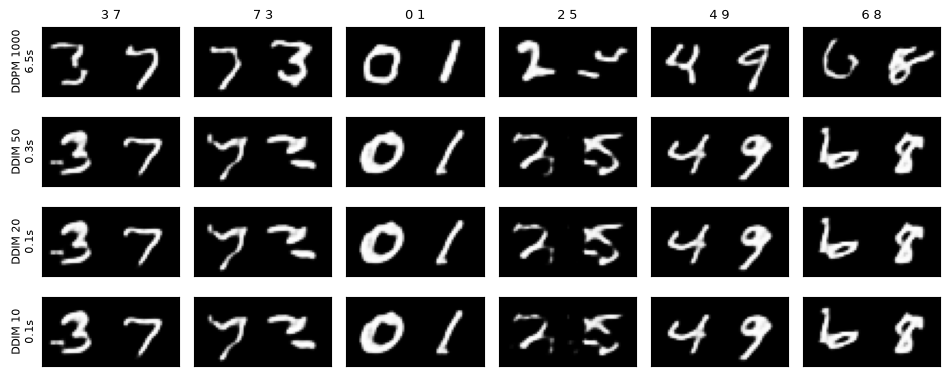

In [3]:
def show_pairs(rows, row_names, pairs):
    fig, axes = plt.subplots(len(rows), len(pairs), figsize=(len(pairs) * 1.6, len(rows) * 1.0), squeeze=False)
    for r, (images, name) in enumerate(zip(rows, row_names)):
        for c, image in enumerate(images):
            ax = axes[r, c]
            ax.imshow(image[0], cmap='gray')
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(f'{pairs[c][0]} {pairs[c][1]}', fontsize=9)
        axes[r, 0].set_ylabel(name, fontsize=8)
    plt.tight_layout()
    plt.show()


@torch.no_grad()
def decode(z):
    return decoder(z / scale_factor).cpu()


guidance_scale = 3.0
pairs = [[3, 7], [7, 3], [0, 1], [2, 5], [4, 9], [6, 8]]
labels = torch.tensor(pairs, device=device)
torch.manual_seed(0)
x_T = torch.randn((len(labels), latent_ch, 8, 16), device=device)

rows, row_names = [], []
start = time.perf_counter()
rows.append(decode(diffuser.ddpm_sample(model, x_T, labels, guidance_scale)))
row_names.append(f'DDPM 1000\n{time.perf_counter() - start:.1f}s')
for num_steps in [50, 20, 10]:
    start = time.perf_counter()
    rows.append(decode(diffuser.ddim_sample(model, x_T, labels, guidance_scale, num_steps)))
    row_names.append(f'DDIM {num_steps}\n{time.perf_counter() - start:.1f}s')

show_pairs(rows, row_names, pairs)

### 새 노이즈를 더하는지 확인
- 같은 시작 노이즈로 각 샘플러를 두 번씩 실행하고, 두 결과 z의 최대 차이를 본다.
- DDPM은 단계마다 새 노이즈를 뽑으므로 두 결과가 다르다. DDIM은 새 노이즈를 더하지 않으므로 두 결과가 같다.

100%|██████████| 1000/1000 [00:06<00:00, 164.68it/s]


DDPM 두 번의 z 최대 차이: 5.8524
DDIM 두 번의 z 최대 차이: 0.0000


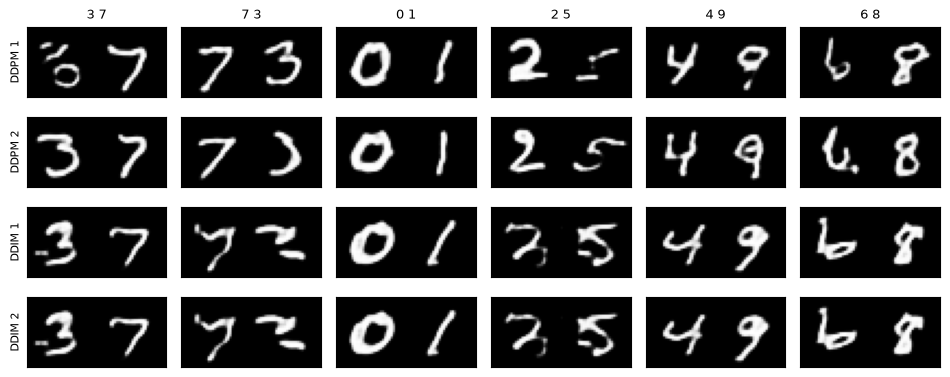

In [4]:
ddpm_a = diffuser.ddpm_sample(model, x_T, labels, guidance_scale)
ddpm_b = diffuser.ddpm_sample(model, x_T, labels, guidance_scale)
ddim_a = diffuser.ddim_sample(model, x_T, labels, guidance_scale)
ddim_b = diffuser.ddim_sample(model, x_T, labels, guidance_scale)
print(f'DDPM 두 번의 z 최대 차이: {(ddpm_a - ddpm_b).abs().max():.4f}')
print(f'DDIM 두 번의 z 최대 차이: {(ddim_a - ddim_b).abs().max():.4f}')

show_pairs([decode(ddpm_a), decode(ddpm_b), decode(ddim_a), decode(ddim_b)],
           ['DDPM 1', 'DDPM 2', 'DDIM 1', 'DDIM 2'], pairs)